# PathSnap - 04 Bayesian hyperparameter optimisation (selected model)

* Model: the one chosen in `03_models.ipynb` (`outputs/models/selection.json`).
* Strategy: **Optuna TPE sampler** (Tree-structured Parzen Estimator), a sequential model-based (Bayesian) optimiser: after a few random
  trials it models which regions of the search space give good scores and samples there.
* Objective: **maximise mean point-level Top-1 accuracy** over **GroupKFold(3) by trip on the 80 train trips** (3 folds keep the budget feasible).
* student_test is used only after the search, to compare tuned vs untuned. Evaluator data is never used.

In [1]:
import sys, time, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import optuna, joblib
from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold

sys.path.insert(0, str(Path.cwd().parent / "src"))
import features as F
from features import FEATURES
from metrics import evaluate, load_arcs, top1_per_point
from models import make_models, SEED

ROOT = Path.cwd().parent
FEAT, MOD = ROOT / "outputs" / "features", ROOT / "outputs" / "models"
OUT = ROOT / "outputs" / "tuning"; (OUT / "plots").mkdir(parents=True, exist_ok=True)
ART = ROOT / "artifacts"; ART.mkdir(exist_ok=True)
sel = json.load(open(MOD / "selection.json")); print(sel)
assert sel["selected_model"] == "LightGBM", "search space below is written for LightGBM"
ctr = pd.read_parquet(FEAT / "candidates_train.parquet"); ptr = pd.read_parquet(FEAT / "points_train.parquet")
cte = pd.read_parquet(FEAT / "candidates_student_test.parquet"); pte = pd.read_parquet(FEAT / "points_student_test.parquet")
arcs = {**load_arcs("train"), **load_arcs("student_test")}
lab = ctr[ctr.label >= 0].reset_index(drop=True)
trips = lab.trip_id.unique()

{'selected_model': 'LightGBM', 'rule': 'highest CV point-level Top-1 accuracy; tie-break lower CV log loss'}


## 1. Search space (justification)
| Hyperparameter | Range | Why |
|---|---|---|
| num_leaves | 15-255 (log) | tree complexity; default 31, we started at 63 |
| learning_rate | 0.01-0.2 (log) | step size; trades rounds vs. overfitting |
| n_estimators | 100-800 | number of boosting rounds (training curve in 03 flattened in this range) |
| min_child_samples | 10-300 (log) | minimum rows per leaf, regularises noisy labels |
| subsample (+freq 1) | 0.5-1.0 | row bagging for variance reduction |
| colsample_bytree | 0.5-1.0 | feature bagging; several features are correlated (d_prev/d_next) |
| reg_lambda | 1e-3-10 (log) | L2 regularisation on leaf values |

In [2]:
def top1_cv(params, n_splits=3):
    scores = []
    for tr_i, va_i in GroupKFold(n_splits=n_splits).split(trips, groups=trips):
        tr_t, va_t = set(trips[tr_i]), set(trips[va_i])
        a = lab[lab.trip_id.isin(tr_t)]; c_va = ctr[ctr.trip_id.isin(va_t)]
        m = LGBMClassifier(**params, subsample_freq=1, random_state=SEED, verbose=-1, n_jobs=-1).fit(a[FEATURES], a.label)
        top = top1_per_point(c_va, m.predict_proba(c_va[FEATURES])[:, 1])
        p_va = ptr[ptr.trip_id.isin(va_t) & (ptr.true_arc >= 0)]
        scores.append((top.merge(p_va[["trip_id", "point_idx"]]).label == 1).sum() / len(p_va))
    return float(np.mean(scores))

def objective(trial):
    params = {"num_leaves": trial.suggest_int("num_leaves", 15, 255, log=True),
              "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
              "n_estimators": trial.suggest_int("n_estimators", 100, 800, step=50),
              "min_child_samples": trial.suggest_int("min_child_samples", 10, 300, log=True),
              "subsample": trial.suggest_float("subsample", 0.5, 1.0),
              "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
              "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True)}
    return top1_cv(params)

untuned = {"num_leaves": 63, "learning_rate": 0.05, "n_estimators": 300, "min_child_samples": 20, "subsample": 1.0, "colsample_bytree": 1.0, "reg_lambda": 0.0}
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name="lgbm_top1")
study.enqueue_trial({k: v for k, v in untuned.items() if k != "reg_lambda"} | {"reg_lambda": 1e-3})   # trial 0 = (almost) the untuned config
t0 = time.time()
study.optimize(objective, n_trials=25)
opt_time = time.time() - t0
trials = study.trials_dataframe(); trials.to_csv(OUT / "optuna_trials.csv", index=False)
print(f"{len(trials)} trials in {opt_time/60:.1f} min; best CV(3) Top-1 = {study.best_value:.4f}")
print("best params:", study.best_params)
trials.sort_values("value", ascending=False).head(8)

25 trials in 14.4 min; best CV(3) Top-1 = 0.8603
best params: {'num_leaves': 138, 'learning_rate': 0.02630748751678775, 'n_estimators': 600, 'min_child_samples': 12, 'subsample': 0.5774912745607391, 'colsample_bytree': 0.9907796453307647, 'reg_lambda': 9.986332503136188}


,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_lambda,params_subsample,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state
12,12,0.860275,2026-11-18 11:26:13.252649,2026-11-18 11:27:07.196657,0 days 00:00:53.944008,0.990780,0.026307,12,600,138,9.986333,0.577491,NaN,"{""colsample_bytree"": 0.9907796453307647, ""lear...",COMPLETE
13,13,0.860251,2026-11-18 11:27:07.196689,2026-11-18 11:28:04.889769,0 days 00:00:57.693080,0.957861,0.021445,12,550,223,0.328878,0.688250,NaN,"{""colsample_bytree"": 0.9578607220609597, ""lear...",COMPLETE
22,22,0.860020,2026-11-18 11:34:38.812101,2026-11-18 11:35:11.866658,0 days 00:00:33.054557,0.915192,0.026834,19,450,108,0.911973,0.536258,NaN,"{""colsample_bytree"": 0.9151924167444779, ""lear...",COMPLETE
21,21,0.859924,2026-11-18 11:34:03.479827,2026-11-18 11:34:38.812071,0 days 00:00:35.332244,0.969882,0.028335,11,550,95,0.571846,0.532322,NaN,"{""colsample_bytree"": 0.96988221453748, ""learni...",COMPLETE
24,24,0.859717,2026-11-18 11:35:52.776486,2026-11-18 11:36:37.815818,0 days 00:00:45.039332,0.889326,0.024601,10,450,201,0.112559,0.533881,NaN,"{""colsample_bytree"": 0.8893263268674861, ""lear...",COMPLETE
14,14,0.859648,2026-11-18 11:28:04.889796,2026-11-18 11:28:40.308548,0 days 00:00:35.418752,0.984684,0.022956,12,400,164,0.268411,0.747747,NaN,"{""colsample_bytree"": 0.9846837747818029, ""lear...",COMPLETE
16,16,0.859613,2026-11-18 11:29:17.578343,2026-11-18 11:30:17.431330,0 days 00:00:59.852987,0.949645,0.022234,11,600,208,0.004980,0.829931,NaN,"{""colsample_bytree"": 0.9496454888331125, ""lear...",COMPLETE
17,17,0.859603,2026-11-18 11:30:17.431358,2026-11-18 11:30:59.303328,0 days 00:00:41.871970,0.864311,0.010963,10,550,118,0.086125,0.654057,NaN,"{""colsample_bytree"": 0.8643108867014817, ""lear...",COMPLETE


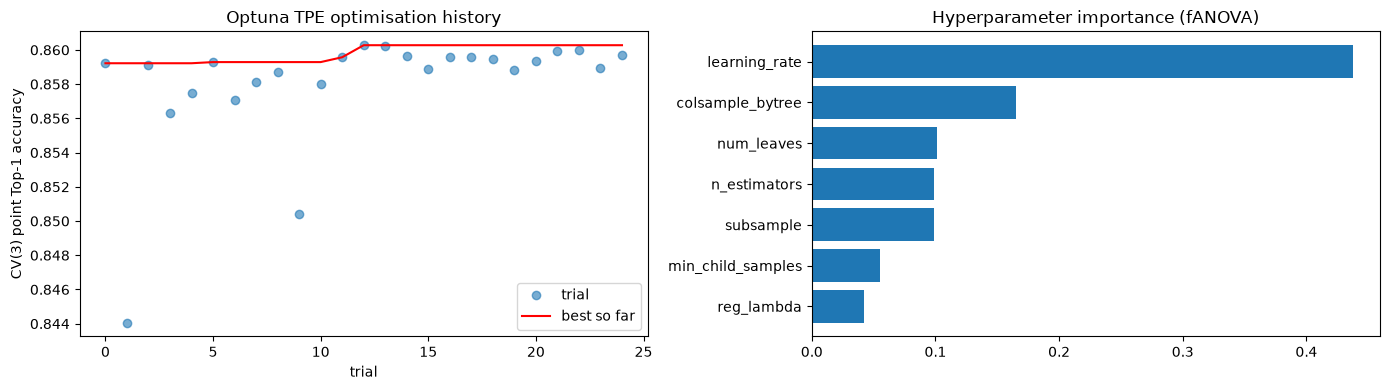

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
v = trials.value.values
ax[0].plot(v, "o", alpha=.6, label="trial"); ax[0].plot(np.maximum.accumulate(v), "r-", label="best so far")
ax[0].set(title="Optuna TPE optimisation history", xlabel="trial", ylabel="CV(3) point Top-1 accuracy"); ax[0].legend()
imp = optuna.importance.get_param_importances(study)
ax[1].barh(list(imp)[::-1], list(imp.values())[::-1]); ax[1].set(title="Hyperparameter importance (fANOVA)")
plt.tight_layout(); plt.savefig(OUT / "plots/01_optuna_history.png", dpi=130); plt.show()

## 2. Tuned vs untuned (same 5 folds as 03, same student_test)

In [4]:
tuned = study.best_params
def cv5(params):
    rows = []
    for tr_i, va_i in GroupKFold(n_splits=5).split(trips, groups=trips):
        tr_t, va_t = set(trips[tr_i]), set(trips[va_i])
        a = lab[lab.trip_id.isin(tr_t)]; c_va = ctr[ctr.trip_id.isin(va_t)]
        m = LGBMClassifier(**params, subsample_freq=1, random_state=SEED, verbose=-1).fit(a[FEATURES], a.label)
        rows.append(evaluate(c_va, m.predict_proba(c_va[FEATURES])[:, 1], ptr[ptr.trip_id.isin(va_t)], arcs))
    return pd.DataFrame(rows)

comp = {}
for name, params in [("untuned", untuned), ("tuned", tuned)]:
    cvr = cv5(params)
    t0 = time.time(); m = LGBMClassifier(**params, subsample_freq=1, random_state=SEED, verbose=-1).fit(lab[FEATURES], lab.label); fit_t = time.time() - t0
    t0 = time.time(); prob = m.predict_proba(cte[FEATURES])[:, 1]; inf_t = time.time() - t0
    r = evaluate(cte, prob, pte, arcs)
    comp[name] = {"cv_macro_f1": cvr.macro_f1.mean(), "cv_top1_acc": cvr.top1_acc.mean(), "cv_log_loss": cvr.log_loss.mean(),
                  "test_top1_acc": r["top1_acc"], "test_macro_f1": r["macro_f1"], "test_log_loss": r["log_loss"],
                  "test_route_continuity": r["route_continuity"], "fit_time_s": fit_t, "inference_ms_per_1k_points": inf_t * 1e6 / len(pte)}
    if name == "tuned": final = m
comp = pd.DataFrame(comp); comp.to_csv(OUT / "tuned_vs_untuned.csv"); comp.round(4)

,untuned,tuned
cv_macro_f1,0.9145,0.9155
cv_top1_acc,0.8615,0.8633
cv_log_loss,0.1183,0.1174
test_top1_acc,0.8770,0.8820
test_macro_f1,0.9238,0.9261
test_log_loss,0.1039,0.1009
test_route_continuity,0.9463,0.9499
fit_time_s,5.3980,18.6092
inference_ms_per_1k_points,15.4805,54.6924


## 3. Export the final classifier

In [5]:
joblib.dump(final, ART / "model.joblib")
json.dump({"model": "LightGBM", "params": tuned, "features": FEATURES, "radius_m": F.RADIUS, "max_cands": F.MAX_CANDS,
           "gap_split_s": F.GAP_SPLIT_S, "label_max_dist_m": F.LABEL_MAX_DIST, "trained_on": "80 train trips (labelled rows)",
           "optuna": {"sampler": "TPE", "seed": SEED, "n_trials": len(trials), "cv": "GroupKFold(3) by trip", "objective": "point Top-1 accuracy",
                      "best_cv_top1": study.best_value, "search_minutes": round(opt_time / 60, 2)}},
          open(ART / "model_config.json", "w"), indent=2)
print("saved artifacts/model.joblib and artifacts/model_config.json")

saved artifacts/model.joblib and artifacts/model_config.json
